# Fine-Tuning: сравнение двух моделей

Сравниваю две предобученные архитектуры на подвыборке Flowers: 180 открытых фотографий, три класса. Снимки взяты из внешнего набора, а не сделаны мной. Это ограничение относительно условия лабораторной.


In [1]:
from pathlib import Path
import os, sys, json, subprocess
from IPython.display import display, Image
import pandas as pd
# Найти корень независимо от рабочей папки Jupyter.
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'experiments/train.py').exists())
os.chdir(root)
print(root)


/home/runner/work/fine-tuning-flowers/fine-tuning-flowers


## Данные

Три класса: daisy, roses, sunflowers. По 60 снимков, общий сплит 126/27/27. Исходные файлы сохранены вместе с лицензией, авторами и хешами. Сбор — скачивание и воспроизводимый отбор из TensorFlow Flowers.


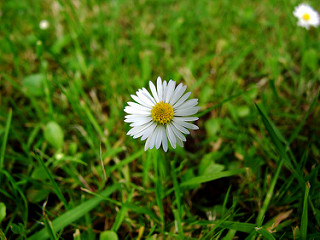

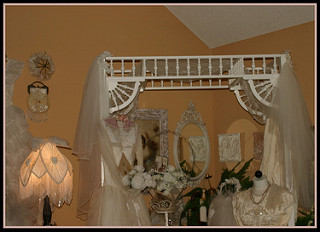

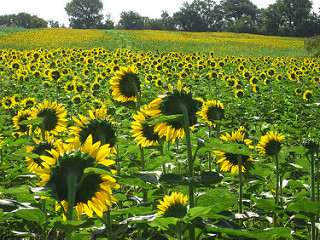

{'daisy': 60, 'roses': 60, 'sunflowers': 60}


In [2]:
from PIL import Image as PILImage
import matplotlib.pyplot as plt
raw = root/'experiments/data/raw'
counts = {}
for folder in sorted(raw.iterdir()):
    if folder.is_dir():
        images = [p for p in folder.iterdir() if p.suffix.lower() in {'.jpg','.jpeg','.png','.webp'}]
        counts[folder.name] = len(images)
        if images:
            display(Image(filename=str(images[0]), width=220))
print(counts)
assert len(counts)>=3 and min(counts.values())>=30, 'Добавьте собственные фотографии'


## План эксперимента

Сравниваю ResNet18 и MobileNetV3 Small. Первая использует остаточные связи, вторая рассчитана на небольшие вычислительные затраты. Для каждой проверяю learning rate 0.001 и 0.0003. Остальные параметры одинаковые: 6 эпох, 2 эпохи замороженного backbone, batch size 16. Это небольшой поиск для CPU, а не исчерпывающая оптимизация. Лучшую конфигурацию выбираю только по validation.


In [3]:
models = {'resnet':'resnet18.a1_in1k', 'mobile':'mobilenetv3_small_100.lamb_in1k'}
for family, model in models.items():
    for lr in [0.001, 0.0003]:
        name = f'{family}_lr{lr}'
        path = root/'experiments/runs'/name
        if (path/'summary.json').exists():
            print('Уже выполнен:', name)
            continue
        subprocess.run([sys.executable,'-m','experiments.train','--model',model,'--lr',str(lr),'--backbone-lr',str(lr/10),'--run-name',name], check=True)


{"epoch": 1, "train_loss": 1.1369058253273132, "train_accuracy": 0.3412698412698413, "val_loss": 1.0702959343239113, "val_accuracy": 0.2962962962962963, "head_lr": 0.001}


{"epoch": 2, "train_loss": 0.9964653404932173, "train_accuracy": 0.5634920634920635, "val_loss": 0.9767045268306026, "val_accuracy": 0.5185185185185185, "head_lr": 0.0005}


{"epoch": 3, "train_loss": 1.0230332877900865, "train_accuracy": 0.5158730158730159, "val_loss": 0.9550019370185004, "val_accuracy": 0.5925925925925926, "head_lr": 0.001}


{"epoch": 4, "train_loss": 0.9162722144808088, "train_accuracy": 0.6746031746031746, "val_loss": 0.8971918953789605, "val_accuracy": 0.7407407407407407, "head_lr": 0.0008535533905932737}


{"epoch": 5, "train_loss": 0.837434676904527, "train_accuracy": 0.8095238095238095, "val_loss": 0.8652871096575702, "val_accuracy": 0.8148148148148148, "head_lr": 0.0005}


...

{"epoch": 2, "train_loss": 6.36348949916779, "train_accuracy": 0.2619047619047619, "val_loss": 3.8906707763671875, "val_accuracy": 0.4074074074074074, "head_lr": 0.00015}


{"epoch": 3, "train_loss": 4.531302743487888, "train_accuracy": 0.3968253968253968, "val_loss": 1.951536390516493, "val_accuracy": 0.6296296296296297, "head_lr": 0.0003}


{"epoch": 4, "train_loss": 1.6862267161172533, "train_accuracy": 0.6507936507936508, "val_loss": 1.5592037483497903, "val_accuracy": 0.7407407407407407, "head_lr": 0.00025606601717798207}


{"epoch": 5, "train_loss": 1.3417206472820706, "train_accuracy": 0.7142857142857143, "val_loss": 1.4092189647533275, "val_accuracy": 0.7407407407407407, "head_lr": 0.00014999999999999996}


{"epoch": 6, "train_loss": 1.1316132375172205, "train_accuracy": 0.6746031746031746, "val_loss": 1.287581902963144, "val_accuracy": 0.7777777777777778, "head_lr": 4.393398282201787e-05}


## Кривые и выбор модели

Train accuracy считается с аугментациями, validation — на детерминированных изображениях. Поэтому validation иногда может быть выше train. Признак переобучения — снижение train loss при росте validation loss; одного разрыва accuracy недостаточно.


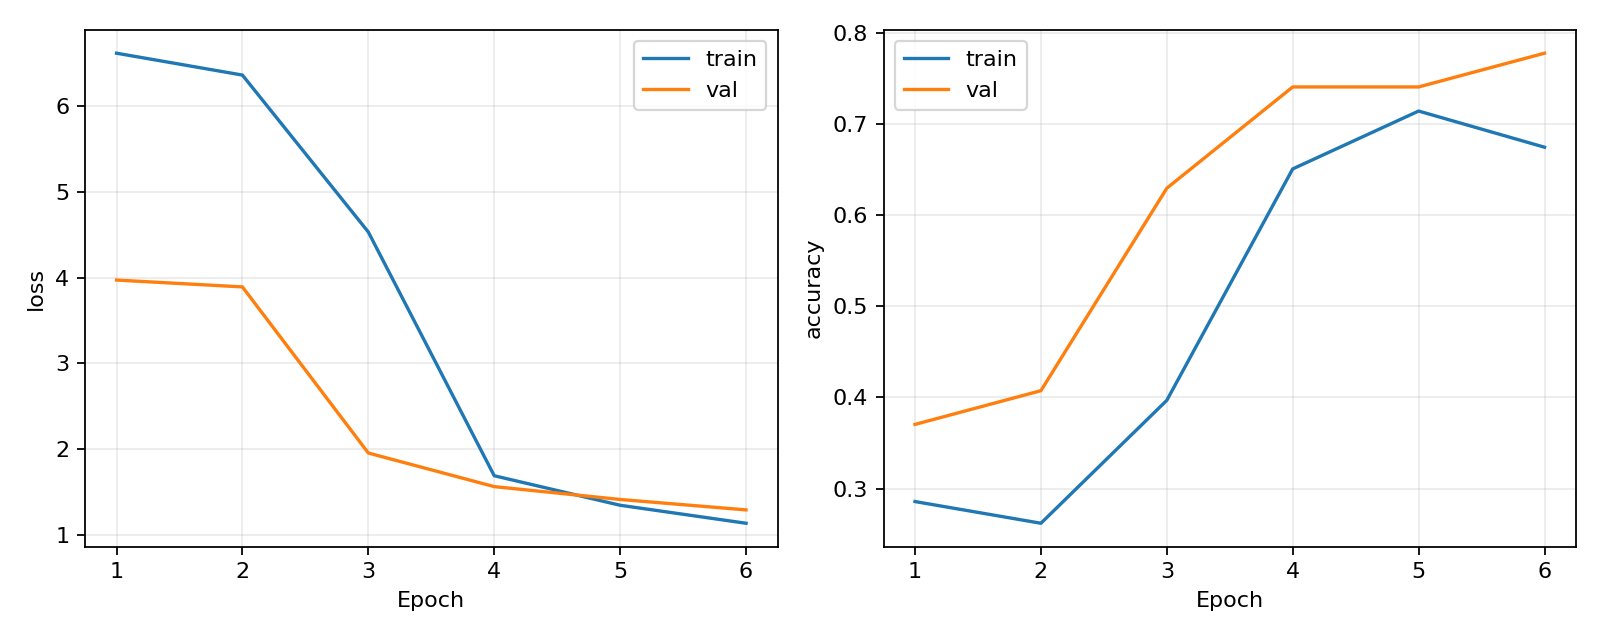

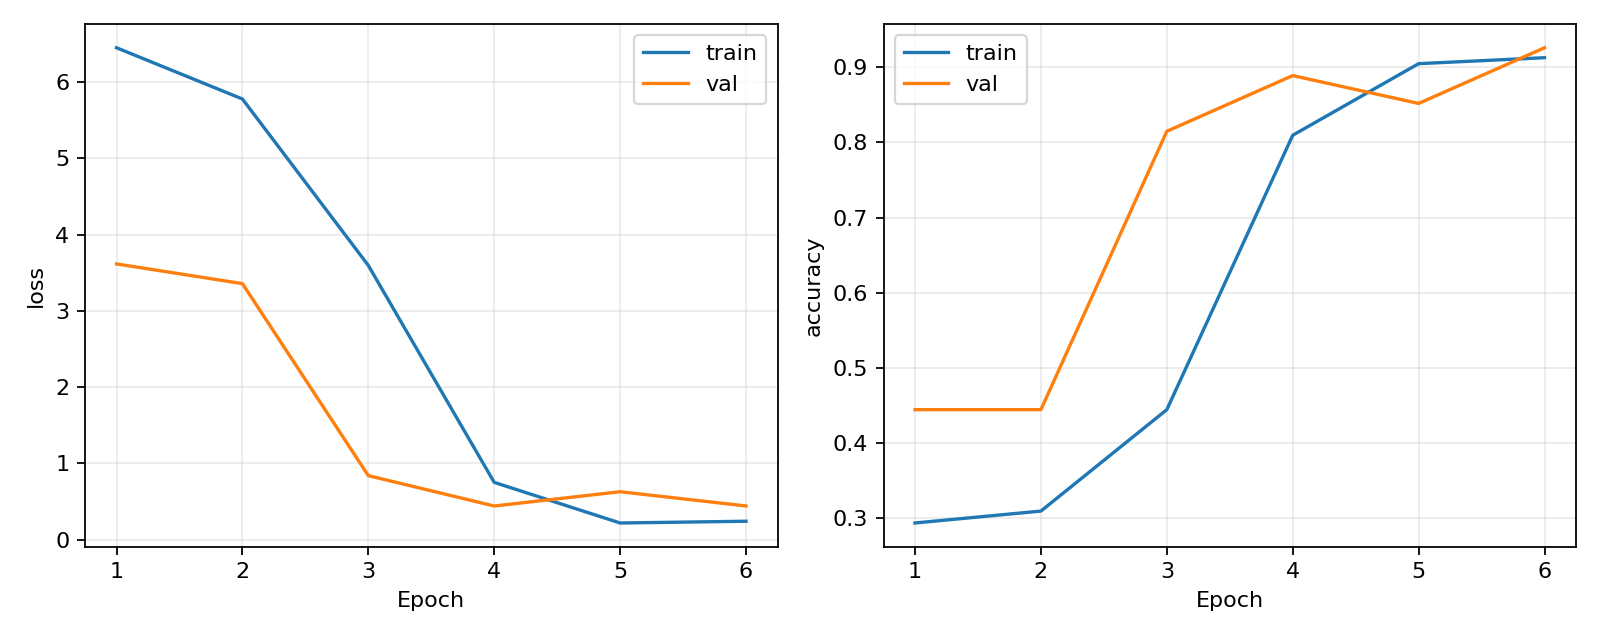

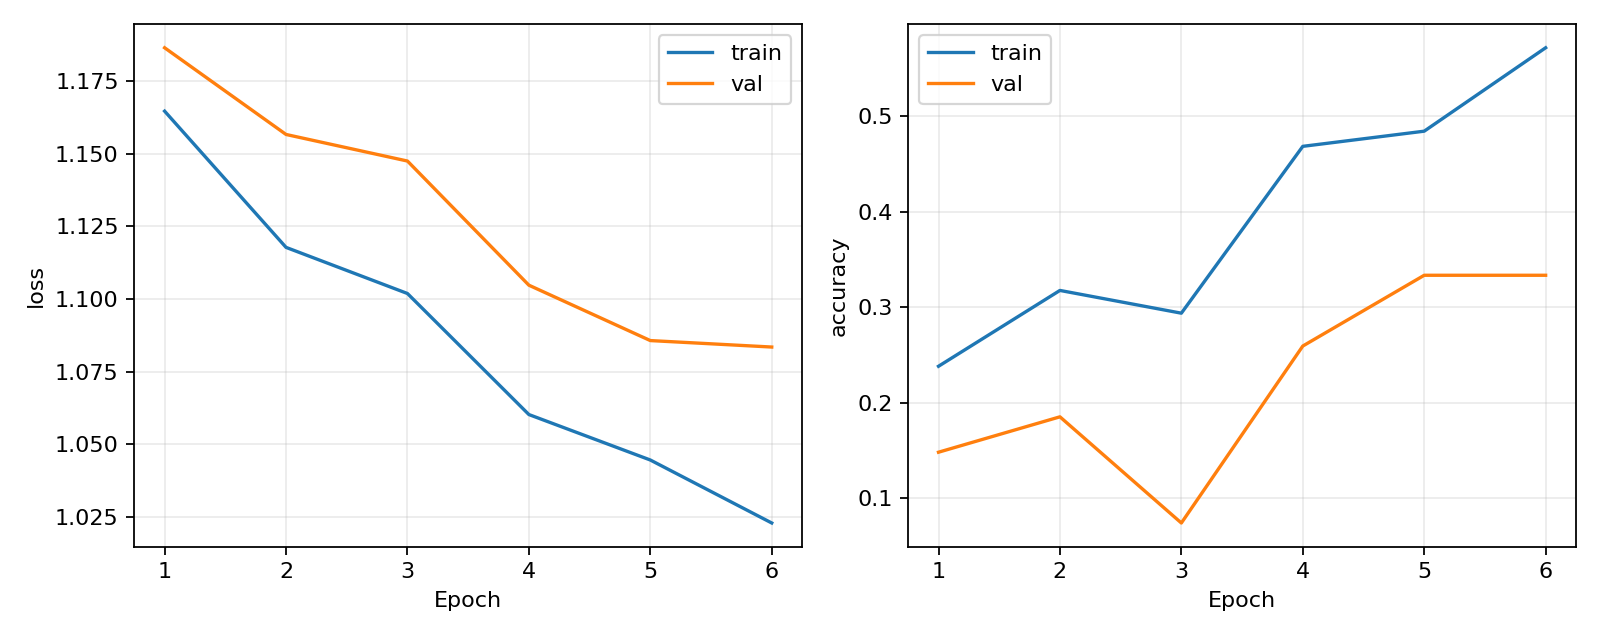

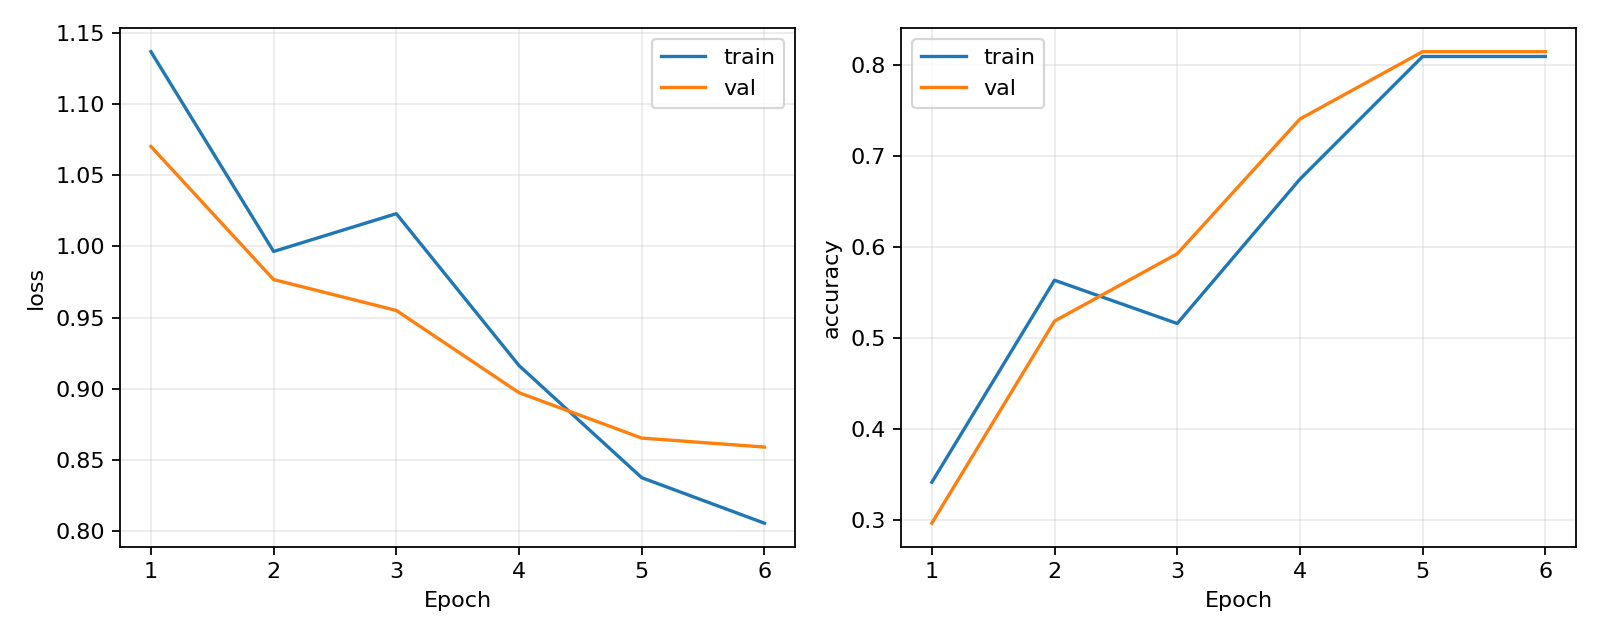

,run,model,lr,best_val_accuracy,seconds,parameters
1,mobile_lr0.001,mobilenetv3_small_100.lamb_in1k,0.0010,0.925926,8.162053,1520931
3,resnet_lr0.001,resnet18.a1_in1k,0.0010,0.814815,19.328424,11178051
0,mobile_lr0.0003,mobilenetv3_small_100.lamb_in1k,0.0003,0.777778,8.359579,1520931
2,resnet_lr0.0003,resnet18.a1_in1k,0.0003,0.333333,18.323209,11178051


In [4]:
rows=[]
for p in sorted((root/'experiments/runs').glob('*/summary.json')):
    summary=json.loads(p.read_text())
    cfg=json.loads((p.parent/'config.json').read_text())
    rows.append({'run':p.parent.name,'model':cfg['model'],'lr':cfg['lr'],**summary})
    display(Image(filename=str(p.parent/'learning_curves.png')))
comparison=pd.DataFrame(rows).sort_values('best_val_accuracy', ascending=False)
display(comparison)


## Независимая тестовая оценка и ONNX

Выполняю только после завершения подбора. Тестовая выборка не участвует в выборе победителя. При малом наборе одна ошибка заметно меняет accuracy, поэтому вместе с ней рассматриваю абсолютные значения матрицы ошибок.


Выбрана mobile_lr0.001; ONNX сохранён в /home/runner/work/fine-tuning-flowers/fine-tuning-flowers/experiments/models


mobile_lr0.001 test accuracy: 0.7407407407407407


,precision,recall,f1-score,support
daisy,0.777778,0.777778,0.777778,9.000000
roses,0.777778,0.777778,0.777778,9.000000
sunflowers,0.666667,0.666667,0.666667,9.000000
accuracy,0.740741,0.740741,0.740741,0.740741
macro avg,0.740741,0.740741,0.740741,27.000000
weighted avg,0.740741,0.740741,0.740741,27.000000


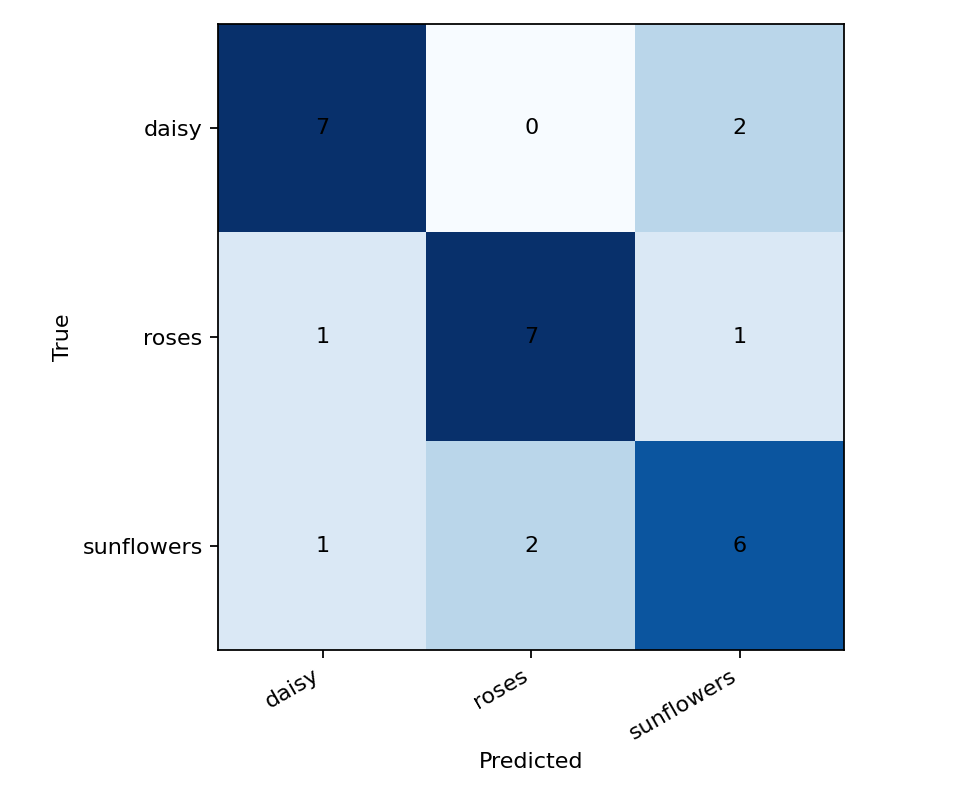

Ошибок: 7
daisy/2001380507_19488ff96a_n.jpg предсказанный индекс: 2


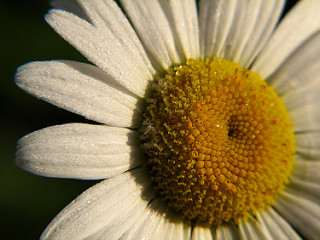

daisy/4144275653_7c02d47d9b.jpg предсказанный индекс: 2


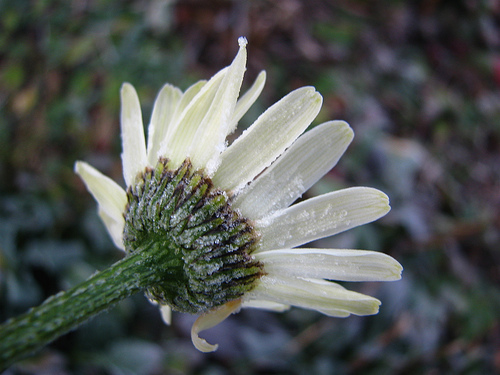

roses/3713368809_eba7fa2fbf_m.jpg предсказанный индекс: 2


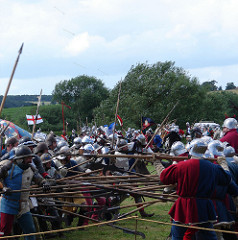

roses/3074406590_91c697c805_n.jpg предсказанный индекс: 0


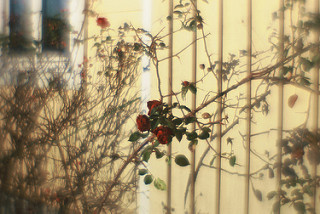

sunflowers/5069564563_ae03792c3c_m.jpg предсказанный индекс: 1


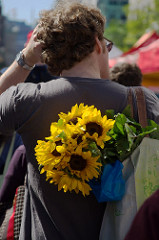

sunflowers/9511172241_8aee411e2e.jpg предсказанный индекс: 1


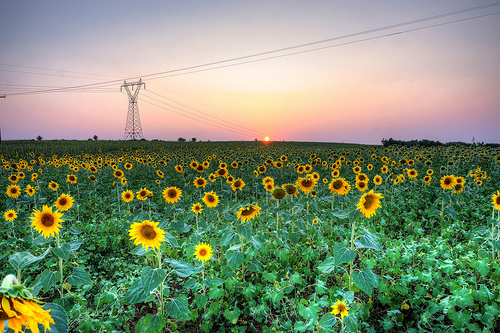

resnet_lr0.001 test accuracy: 0.8518518518518519


,precision,recall,f1-score,support
daisy,0.818182,1.000000,0.900000,9.000000
roses,0.888889,0.888889,0.888889,9.000000
sunflowers,0.857143,0.666667,0.750000,9.000000
accuracy,0.851852,0.851852,0.851852,0.851852
macro avg,0.854738,0.851852,0.846296,27.000000
weighted avg,0.854738,0.851852,0.846296,27.000000


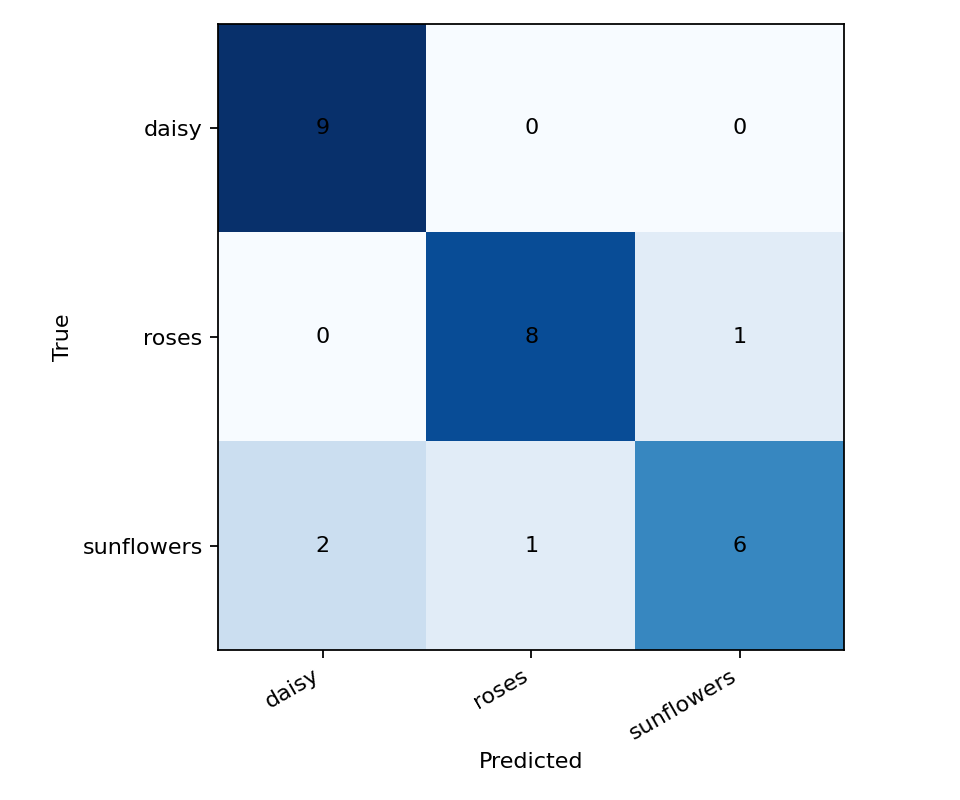

Ошибок: 4
roses/9300754115_dd79670066_n.jpg предсказанный индекс: 2


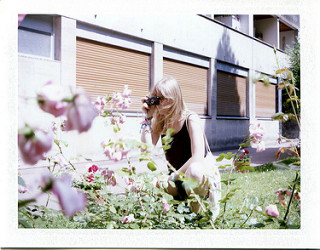

sunflowers/14678298676_6db8831ee6_m.jpg предсказанный индекс: 0


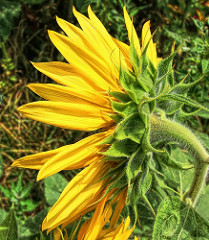

sunflowers/2443921986_d4582c123a.jpg предсказанный индекс: 0


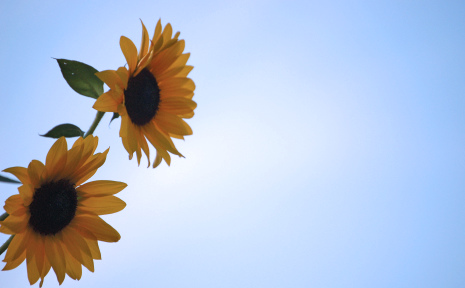

sunflowers/4814106562_7c3564d2d9_n.jpg предсказанный индекс: 1


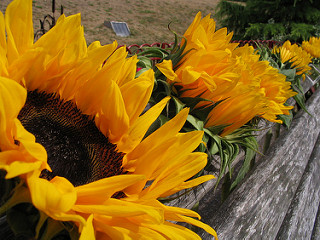

{
  "images_checked": 27,
  "max_abs_error": 6.771087646484375e-05
}


In [5]:
subprocess.run([sys.executable,'-m','experiments.train','--finalize'],check=True)
for p in sorted((root/'experiments/runs').glob('*/test_metrics.json')):
    metrics=json.loads(p.read_text())
    print(p.parent.name, 'test accuracy:', metrics['accuracy'])
    display(pd.DataFrame(metrics['report']).T)
    display(Image(filename=str(p.parent/'confusion_matrix.png')))
    predictions=json.loads((p.parent/'test_predictions.json').read_text())
    mistakes=[x for x in predictions if x['label']!=x['prediction']]
    print('Ошибок:',len(mistakes))
    for item in mistakes[:6]:
        print(item['path'], 'предсказанный индекс:', item['prediction'])
        display(Image(filename=str(raw/item['path']),width=200))
print((root/'experiments/models/export_check.json').read_text())


## Результаты выполненных экспериментов

| Запуск | lr | Validation accuracy | Test accuracy | Время, с | Параметры |
|---|---:|---:|---:|---:|---:|
| mobile_lr0.0003 | 0.0003 | 0.778 | не оценивалась | 8.4 | 1,520,931 |
| mobile_lr0.001 | 0.001 | 0.926 | 0.741 | 8.2 | 1,520,931 |
| resnet_lr0.0003 | 0.0003 | 0.333 | не оценивалась | 18.3 | 11,178,051 |
| resnet_lr0.001 | 0.001 | 0.815 | 0.852 | 19.3 | 11,178,051 |

По validation выбрана модель **mobilenetv3_small_100.lamb_in1k**, запуск `mobile_lr0.001`. Её test accuracy составила **0.741** на 27 снимках.

Набор небольшой: одна ошибка на test меняет accuracy примерно на 3.7 процентного пункта. Поэтому различие в одну фотографию не даёт надёжного доказательства превосходства архитектуры.

Для `mobile_lr0.001` самая частая путаница: sunflowers → roses, 2 снимков. Примеры ошибок показаны в ноутбуке.
К последней эпохе train loss уменьшилась, а validation loss выше достигнутого минимума. Это повод остановиться на сохранённом checkpoint; по короткой кривой нельзя уверенно установить причину роста.
Для `resnet_lr0.001` самая частая путаница: sunflowers → daisy, 2 снимков. Примеры ошибок показаны в ноутбуке.

Время измерено на одной машине и включает обучение и validation, но не скачивание весов. Число параметров описывает размер модели, а не напрямую её задержку в приложении.

Ограничения: открытые фотографии вместо самостоятельной съёмки, один seed, небольшой test, возможные похожие изображения, отсутствие проверки на другом устройстве. Для улучшения оценки нужны собственные новые снимки и несколько повторов разбиения.


### Почему для приложения выбрана MobileNetV3

При выборе ориентировался на validation, а не на test: 25 правильных ответов
из 27 у MobileNetV3 против 22 из 27 у ResNet18. Дополнительно MobileNetV3
содержит примерно в 7.3 раза меньше параметров и обучилась за 8.2 с против
19.3 с у ResNet18 на том же CPU. Для небольшого локального приложения это
полезный компромисс. Размер ONNX MobileNetV3 около 6 МБ; пример инференса
в проверке приложения занял 2.4 мс. Одно измерение задержки не является
полноценным бенчмарком и не включает декодирование файла.

На test порядок моделей оказался обратным: ResNet18 правильно распознала
23 из 27 снимков (85.2%), MobileNetV3 — 20 из 27 (74.1%). Это расхождение
сохранил в результатах. Оно показывает, что выбор по маленькой validation
выборке нестабилен. Менять победителя на основании test после подбора нельзя:
для следующего исследования нужны новая независимая выборка или несколько
разбиений. Результаты относятся к этим гиперпараметрам и шести эпохам,
а не доказывают преимущество одного семейства моделей в целом.

### Что видно на кривых и ошибочных снимках

У MobileNetV3 при lr=0.001 в первых двух эпохах train loss остаётся выше 5.
После размораживания на третьей эпохе она снижается до 3.59, а к четвёртой —
до 0.75. В этом запуске обучение одного классификатора оказалось недостаточным;
настройка признаков заметно помогла. При lr=0.0003 за тот же бюджет модели
обучились хуже. Особенно это видно у ResNet18: validation accuracy лишь 33.3%.
Более низкий lr здесь не означает более качественную модель; возможно,
ему требуется больше эпох, но это отдельно не проверялось.

В двух ошибках daisy → sunflowers крупная жёлтая сердцевина и радиальные
лепестки визуально напоминают подсолнух. На снимках подсолнухов встречаются
букет на фоне человека и общий план поля: объект занимает другую долю кадра,
чем крупные цветы. Center crop также может убирать полезный контекст.
Это возможные объяснения, а не доказанное устройство признаков модели.

На `roses/3713368809_eba7fa2fbf_m.jpg` изображена группа людей и видимого
цветка нет. Это явная проблема исходной разметки выбранного набора. Снимок
обнаружен при разборе test; я не удалял его после оценки, чтобы не улучшать
метрику задним числом. Перед новым экспериментом стоит проверить весь набор,
зафиксировать исправления и заново разделить данные. Текущие числа сохранены
вместе с этим ограничением.

Экспорт проверен на всех 27 тестовых снимках: классы PyTorch и ONNX совпали,
максимальное абсолютное расхождение logits — 0.0000677. Интерфейс Gradio
создан успешно, его функция классификации возвращает три вероятности,
сумма которых равна единице. Это проверка построения интерфейса и инференса;
ручное взаимодействие с сервером на пользовательском ПК ещё не проверялось.

## Приложение

Запуск из корня: `python -m app.app`.
